In [ ]:
import os
import shutil
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Source paths on your Google Drive (handles spaces safely)
drive_val_images = "/content/drive/MyDrive/MBRSC dataset/aug_images/val_images/val"
drive_val_masks  = "/content/drive/MyDrive/MBRSC dataset/aug_masks/val_masks/val"

# 3. Local destinations on Colab's fast virtual SSD
local_val_images = "/content/val_images"
local_val_masks  = "/content/val_masks"

# 4. Copy validation images & masks locally (~1 to 2 seconds)
if not os.path.exists(local_val_images):
    shutil.copytree(drive_val_images, local_val_images)
    print("✅ Validation images copied to local runtime!")
else:
    print("ℹ️ Validation images already in local runtime.")

if not os.path.exists(local_val_masks):
    shutil.copytree(drive_val_masks, local_val_masks)
    print("✅ Validation masks copied to local runtime!")
else:
    print("ℹ️ Validation masks already in local runtime.")

# 5. Check if model and dictionary are also in Google Drive
for fname in ["class_dict.csv", "InceptionResNetV2-UNet_int8.tflite"]:
    drive_file = f"/content/drive/MyDrive/MBRSC dataset/{fname}"
    if os.path.exists(drive_file) and not os.path.exists(f"/content/{fname}"):
        shutil.copy(drive_file, f"/content/{fname}")
        print(f"✅ Copied {fname} from Drive to /content/")

print("\n--- LOCAL RUNTIME STATUS ---")
print(f"Validation images ready: {len(os.listdir(local_val_images))}")
print(f"Validation masks ready:  {len(os.listdir(local_val_masks))}")
print(f"Model present:           {os.path.exists('/content/InceptionResNetV2-UNet_int8.tflite')}")
print(f"class_dict.csv present:  {os.path.exists('/content/class_dict.csv')}")

Mounted at /content/drive
✅ Validation images copied to local runtime!
✅ Validation masks copied to local runtime!
✅ Copied class_dict.csv from Drive to /content/

--- LOCAL RUNTIME STATUS ---
Validation images ready: 16
Validation masks ready:  16
Model present:           False
class_dict.csv present:  True


In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix

# Suppress deprecation warnings for clean output
warnings.filterwarnings('ignore')

# Set local paths for inference
val_images_dir = "/content/val_images"
val_masks_dir  = "/content/val_masks"

print("Environment and local paths successfully initialized!")

Environment and local paths successfully initialized!


In [ ]:
# 1. Load class mappings from class_dict.csv
class_dict_df = pd.read_csv("class_dict.csv", index_col=False, skipinitialspace=True)
label_names = list(class_dict_df.name)

label_codes = []
for i in range(len(class_dict_df)):
    label_codes.append((int(class_dict_df.r[i]), int(class_dict_df.g[i]), int(class_dict_df.b[i])))

id2code = {k: v for k, v in enumerate(label_codes)}
code2id = {v: k for k, v in enumerate(label_codes)}

# 2. Function to convert RGB mask PNG to class index map (0 to 5)
def rgb_to_class_indices(rgb_img, colormap=id2code):
    h, w = rgb_img.shape[:2]
    class_map = np.zeros((h, w), dtype=np.int32)
    for class_id, color in colormap.items():
        match = np.all(rgb_img == color, axis=-1)
        class_map[match] = class_id
    return class_map

print("Classes detected:", label_names)
display(class_dict_df)

Classes detected: ['building', 'land', 'road', 'vegetation', 'water', 'unlabeled']


,name,r,g,b
0,building,60,16,152
1,land,132,41,246
2,road,110,193,228
3,vegetation,254,221,58
4,water,226,169,41
5,unlabeled,155,155,155


In [ ]:
# 1. Load Quantized TFLite Model with Multi-Threading (All 4 CPU Cores)
tflite_path = "InceptionResNetV2-UNet_int8.tflite"

interpreter = tf.lite.Interpreter(
    model_path=tflite_path,
    num_threads=4  # <--- Unlocks multi-core CPU execution
)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("✅ Quantized INT8 TFLite Model Loaded Successfully!")
print(f"Input Shape:  {input_details[0]['shape']}, Type: {input_details[0]['dtype']}")
print(f"Output Shape: {output_details[0]['shape']}, Type: {output_details[0]['dtype']}")

# 2. Create 1 synthetic image in memory for pure hardware timing
dummy_input = np.random.randn(1, 512, 512, 3).astype(np.float32)

# 3. Warmup (5 runs to wake up CPU caches and instructions)
print("\nWarming up CPU interpreter (5 runs)...")
for _ in range(5):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()

# 4. Benchmark (20 timed runs to calculate a stable average)
print("Benchmarking multi-threaded CPU inference speed (20 runs)...")
times = []
for _ in range(20):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    times.append((time.perf_counter() - start) * 1000)

tflite_latency_mean = np.mean(times)
tflite_fps = 1000.0 / tflite_latency_mean

print(f"\n--- MULTI-THREADED INT8 SPEED BENCHMARK (20 RUNS) ---")
print(f"Multi-Thread CPU Latency per image: {tflite_latency_mean:.2f} ms")
print(f"Multi-Thread CPU Throughput:        {tflite_fps:.2f} FPS")

✅ Quantized INT8 TFLite Model Loaded Successfully!
Input Shape:  [  1 512 512   3], Type: <class 'numpy.float32'>
Output Shape: [  1 512 512   6], Type: <class 'numpy.float32'>

Warming up CPU interpreter (5 runs)...
Benchmarking multi-threaded CPU inference speed (20 runs)...

--- MULTI-THREADED INT8 SPEED BENCHMARK (20 RUNS) ---
Multi-Thread CPU Latency per image: 15911.85 ms
Multi-Thread CPU Throughput:        0.06 FPS


In [ ]:
all_true = []
all_pred = []

# Filter for image files only (ignoring any hidden OS files)
val_filenames = sorted([
    f for f in os.listdir(val_images_dir)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

print(f"Running INT8 evaluation on {len(val_filenames)} validation images...")

for idx, fname in enumerate(val_filenames):
    # 1. Load and preprocess image (512x512, normalized 0..1 float32)
    img_path = os.path.join(val_images_dir, fname)
    img = Image.open(img_path).convert('RGB').resize((512, 512))
    img_array = np.array(img, dtype=np.float32) / 255.0
    input_data = np.expand_dims(img_array, axis=0)

    # 2. Run Quantized TFLite inference
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    pred = interpreter.get_tensor(output_details[0]['index'])[0]  # Shape: (512, 512, 6)
    pred_class_map = np.argmax(pred, axis=-1)

    # 3. Load matching mask
    base_name = os.path.splitext(fname)[0]
    mask_path = os.path.join(val_masks_dir, base_name + ".png")
    if not os.path.exists(mask_path):
        mask_path = os.path.join(val_masks_dir, base_name + ".jpg")

    mask_img = np.array(Image.open(mask_path).convert('RGB').resize((512, 512)))
    true_class_map = rgb_to_class_indices(mask_img)

    # 4. Collect pixels for confusion matrix & IoU
    all_true.extend(true_class_map.flatten())
    all_pred.extend(pred_class_map.flatten())

    print(f"Processed [{idx+1}/{len(val_filenames)}]: {fname}")

all_true = np.array(all_true)
all_pred = np.array(all_pred)
print("\n✅ All validation images processed successfully!")

Running INT8 evaluation on 16 validation images...
Processed [1/16]: image_t1_001.jpg
Processed [2/16]: image_t1_004.jpg
Processed [3/16]: image_t2_007.jpg
Processed [4/16]: image_t2_008.jpg
Processed [5/16]: image_t3_001.jpg
Processed [6/16]: image_t3_008.jpg
Processed [7/16]: image_t4_007.jpg
Processed [8/16]: image_t4_009.jpg
Processed [9/16]: image_t5_003.jpg
Processed [10/16]: image_t5_004.jpg
Processed [11/16]: image_t6_001.jpg
Processed [12/16]: image_t6_008.jpg
Processed [13/16]: image_t7_004.jpg
Processed [14/16]: image_t7_009.jpg
Processed [15/16]: image_t8_004.jpg
Processed [16/16]: image_t8_005.jpg

✅ All validation images processed successfully!



=== QUANTIZED INT8 TFLITE METRICS SUMMARY ===


,Class,INT8 IoU,INT8 Dice / F1,Precision,Recall
0,building,0.4012,0.5727,0.9023,0.4195
1,land,0.7761,0.8740,0.8101,0.9488
2,road,0.3327,0.4993,0.3820,0.7203
3,vegetation,0.6190,0.7647,0.7270,0.8065
4,water,0.8849,0.9390,0.9123,0.9672
5,unlabeled,0.0509,0.0968,0.3701,0.0557
6,Mean (mIoU / Overall),0.5108,0.6244,0.6840,0.6530
7,5-Class Terrain mIoU,0.6028,0.7299,0.7467,0.7725


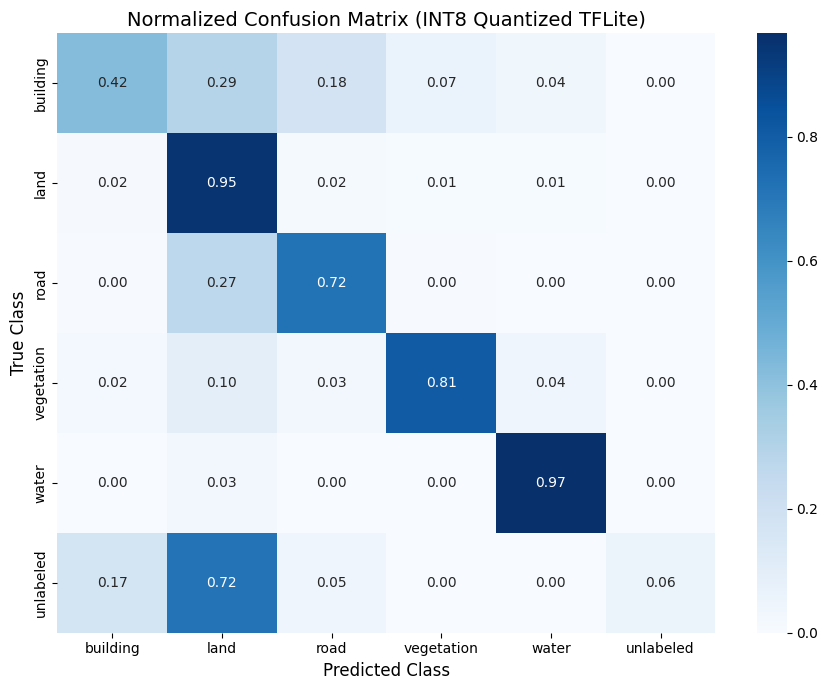

In [ ]:
# 1. Confusion Matrix
classes = label_names
cm = confusion_matrix(all_true, all_pred, labels=range(len(classes)))

# 2. Compute Per-Class IoU, Dice, Precision, Recall
intersection = np.diag(cm)
ground_truth_set = cm.sum(axis=1)
predicted_set = cm.sum(axis=0)
union = ground_truth_set + predicted_set - intersection

iou = intersection / np.maximum(union, 1e-7)
precision = intersection / np.maximum(predicted_set, 1e-7)
recall = intersection / np.maximum(ground_truth_set, 1e-7)
f1_dice = (2 * intersection) / np.maximum(ground_truth_set + predicted_set, 1e-7)

# 3. Create DataFrame
metrics_df = pd.DataFrame({
    'Class': classes,
    'INT8 IoU': np.round(iou, 4),
    'INT8 Dice / F1': np.round(f1_dice, 4),
    'Precision': np.round(precision, 4),
    'Recall': np.round(recall, 4)
})

# Summary Rows: Overall Mean and 5 Genuine Terrain Classes
overall_row = pd.DataFrame([{
    'Class': 'Mean (mIoU / Overall)',
    'INT8 IoU': np.round(np.mean(iou), 4),
    'INT8 Dice / F1': np.round(np.mean(f1_dice), 4),
    'Precision': np.round(np.mean(precision), 4),
    'Recall': np.round(np.mean(recall), 4)
}])

terrain_row = pd.DataFrame([{
    'Class': '5-Class Terrain mIoU',
    'INT8 IoU': np.round(np.mean(iou[:5]), 4),
    'INT8 Dice / F1': np.round(np.mean(f1_dice[:5]), 4),
    'Precision': np.round(np.mean(precision[:5]), 4),
    'Recall': np.round(np.mean(recall[:5]), 4)
}])

metrics_df = pd.concat([metrics_df, overall_row, terrain_row], ignore_index=True)
metrics_df.to_csv("int8_quantized_metrics.csv", index=False)

print("\n=== QUANTIZED INT8 TFLITE METRICS SUMMARY ===")
display(metrics_df)

# 4. Plot Normalized Confusion Matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=classes, yticklabels=classes, cbar=True)
plt.title("Normalized Confusion Matrix (INT8 Quantized TFLite)", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("True Class", fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix_int8.png", dpi=200)
plt.show()

# STATIC Post-Training-Quantization
##### using 100 images as calibration dataset from the training set of 504 images for mapping integers

In [ ]:
import os
import shutil
import zipfile
import tensorflow as tf
from google.colab import drive

# 1. Mount Google Drive
if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

models_dir = "/content/drive/MyDrive/MBRSC dataset/models"
drive_model_path = os.path.join(models_dir, "InceptionResNetV2-UNet.keras")
local_model_path = "/content/InceptionResNetV2-UNet.keras"

# 2. Check Drive model size
drive_size_mb = os.path.getsize(drive_model_path) / (1024 * 1024)
print(f"Master model in Google Drive: {drive_size_mb:.2f} MB")

# 3. Clean up any broken 0-byte local file and force copy fresh from Drive
if os.path.exists(local_model_path):
    local_size = os.path.getsize(local_model_path) / (1024 * 1024)
    # If local file is incomplete (less than 400 MB), delete it
    if local_size < 400:
        print(f"Removing broken local file ({local_size:.2f} MB)...")
        os.remove(local_model_path)

if not os.path.exists(local_model_path):
    print("Copying full master model from Google Drive to local runtime (takes ~15-20s)...")
    shutil.copy(drive_model_path, local_model_path)
    print("✅ Model copied successfully!")

final_size = os.path.getsize(local_model_path) / (1024 * 1024)
print(f"Local model ready: {final_size:.2f} MB")

# 4. Load the master model into RAM
print("\nLoading master model into memory (compile=False)...")
try:
    base_model = tf.keras.models.load_model(local_model_path, compile=False)
except Exception as e:
    print(f"Notice: .keras load gave: {e}\nTrying InceptionResNetV2-UNet.h5 fallback...")
    h5_drive_path = os.path.join(models_dir, "InceptionResNetV2-UNet.h5")
    h5_local_path = "/content/InceptionResNetV2-UNet.h5"
    if not os.path.exists(h5_local_path):
        shutil.copy(h5_drive_path, h5_local_path)
    base_model = tf.keras.models.load_model(h5_local_path, compile=False)

print("\n🎉 Master Model Successfully Loaded!")
print(f"Model Input Shape:  {base_model.input_shape}")
print(f"Model Output Shape: {base_model.output_shape}")

Master model in Google Drive: 423.14 MB
Copying full master model from Google Drive to local runtime (takes ~15-20s)...
✅ Model copied successfully!
Local model ready: 423.14 MB

Loading master model into memory (compile=False)...

🎉 Master Model Successfully Loaded!
Model Input Shape:  (None, 512, 512, 3)
Model Output Shape: (None, 512, 512, 6)


In [ ]:
import os
import shutil
import numpy as np
import tensorflow as tf
from PIL import Image

# 1. Identify Calibration Images from Training Folder
train_drive_dir = "/content/drive/MyDrive/MBRSC dataset/aug_images/train_images/train"
val_local_dir   = "/content/val_images"

# Use training images if available (up to 80 images), otherwise fallback to validation
if os.path.exists(train_drive_dir):
    all_train_files = sorted([
        os.path.join(train_drive_dir, f) for f in os.listdir(train_drive_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])
    calibration_files = all_train_files[:80]
    print(f"Selected {len(calibration_files)} training images for activation calibration.")
else:
    all_val_files = sorted([
        os.path.join(val_local_dir, f) for f in os.listdir(val_local_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])
    calibration_files = all_val_files
    print(f"Training folder not mounted; using {len(calibration_files)} validation images for calibration.")

# 2. Generator that feeds images one-by-one to calibrate INT8 activations
def representative_data_gen():
    for fpath in calibration_files:
        img = Image.open(fpath).convert('RGB').resize((512, 512))
        img_arr = np.array(img, dtype=np.float32) / 255.0
        yield [np.expand_dims(img_arr, axis=0)]

# 3. Configure Static PTQ Converter
converter = tf.lite.TFLiteConverter.from_keras_model(base_model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_data_gen

# Enforce integer quantization on supported operations with float fallback
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8,
    tf.lite.OpsSet.TFLITE_BUILTINS
]

print("\nStarting Static PTQ conversion (calibrating all 244 layer activations)...")
tflite_static_model = converter.convert()

# 4. Save Static PTQ model locally
static_tflite_path = "/content/InceptionResNetV2-UNet_static_int8.tflite"
with open(static_tflite_path, "wb") as f:
    f.write(tflite_static_model)

static_size_mb = os.path.getsize(static_tflite_path) / (1024 * 1024)
print(f"\n✅ Static PTQ Model Created Successfully!")
print(f"Saved to:  {static_tflite_path}")
print(f"File Size: {static_size_mb:.2f} MB")

# 5. Automatically back up the new model to your Google Drive models folder
drive_backup_path = "/content/drive/MyDrive/MBRSC dataset/models/InceptionResNetV2-UNet_static_int8.tflite"
shutil.copy(static_tflite_path, drive_backup_path)
print(f"Backed up to Google Drive: {drive_backup_path}")

Selected 80 training images for activation calibration.

Starting Static PTQ conversion (calibrating all 244 layer activations)...
Saved artifact at '/tmp/tmpbubpzzhs'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 512, 512, 3), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 512, 512, 6), dtype=tf.float32, name=None)
Captures:
  133767391261904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498081872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498083024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498083216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498082256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498082448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498083792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  133768498083984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13376849808340

In [ ]:
import time
import numpy as np
import tensorflow as tf

# 1. Load the new Static PTQ model with 4 CPU threads
static_model_path = "/content/InceptionResNetV2-UNet_static_int8.tflite"

interpreter = tf.lite.Interpreter(
    model_path=static_model_path,
    num_threads=4
)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("✅ Static PTQ Model Loaded Successfully!")
print(f"Input Details:  Shape {input_details[0]['shape']}, Type {input_details[0]['dtype']}")
print(f"Output Details: Shape {output_details[0]['shape']}, Type {output_details[0]['dtype']}")

# 2. Create in-memory test frame
dummy_input = np.random.randn(1, 512, 512, 3).astype(np.float32)

# Warmup runs
print("\nWarming up interpreter (5 runs)...")
for _ in range(5):
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()

# Timed runs with live printouts
print("Benchmarking Static PTQ inference speed (20 timed runs)...")
times = []
for i in range(20):
    start = time.perf_counter()
    interpreter.set_tensor(input_details[0]['index'], dummy_input)
    interpreter.invoke()
    elapsed = (time.perf_counter() - start) * 1000
    times.append(elapsed)
    print(f"  • Run [{i+1}/20]: {elapsed:.2f} ms")

static_latency_mean = np.mean(times)
static_fps = 1000.0 / static_latency_mean

print(f"\n--- STATIC PTQ SPEED BENCHMARK SUMMARY ---")
print(f"Static PTQ CPU Latency: {static_latency_mean:.2f} ms")
print(f"Static PTQ Throughput:  {static_fps:.2f} FPS")

✅ Static PTQ Model Loaded Successfully!
Input Details:  Shape [  1 512 512   3], Type <class 'numpy.float32'>
Output Details: Shape [  1 512 512   6], Type <class 'numpy.float32'>

Warming up interpreter (5 runs)...
Benchmarking Static PTQ inference speed (20 timed runs)...
  • Run [1/20]: 4193.65 ms
  • Run [2/20]: 4085.07 ms
  • Run [3/20]: 4195.62 ms
  • Run [4/20]: 4071.55 ms
  • Run [5/20]: 4019.77 ms
  • Run [6/20]: 4203.57 ms
  • Run [7/20]: 4054.34 ms
  • Run [8/20]: 4284.14 ms
  • Run [9/20]: 4032.97 ms
  • Run [10/20]: 4067.05 ms
  • Run [11/20]: 4114.76 ms
  • Run [12/20]: 4078.27 ms
  • Run [13/20]: 4061.15 ms
  • Run [14/20]: 4549.78 ms
  • Run [15/20]: 4023.09 ms
  • Run [16/20]: 4449.14 ms
  • Run [17/20]: 4655.67 ms
  • Run [18/20]: 4201.23 ms
  • Run [19/20]: 4083.28 ms
  • Run [20/20]: 4112.48 ms

--- STATIC PTQ SPEED BENCHMARK SUMMARY ---
Static PTQ CPU Latency: 4176.83 ms
Static PTQ Throughput:  0.24 FPS


In [ ]:
all_true_static = []
all_pred_static = []

# Filter for validation image files
val_filenames = sorted([
    f for f in os.listdir(val_images_dir)
    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
])

print(f"Running Static PTQ evaluation on {len(val_filenames)} validation images...")

for idx, fname in enumerate(val_filenames):
    # 1. Load and normalize validation image (512x512)
    img_path = os.path.join(val_images_dir, fname)
    img = Image.open(img_path).convert('RGB').resize((512, 512))
    img_array = np.array(img, dtype=np.float32) / 255.0
    input_data = np.expand_dims(img_array, axis=0)

    # 2. Run Static PTQ inference
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    pred = interpreter.get_tensor(output_details[0]['index'])[0]  # Shape: (512, 512, 6)
    pred_class_map = np.argmax(pred, axis=-1)

    # 3. Load matching ground truth mask
    base_name = os.path.splitext(fname)[0]
    mask_path = os.path.join(val_masks_dir, base_name + ".png")
    if not os.path.exists(mask_path):
        mask_path = os.path.join(val_masks_dir, base_name + ".jpg")

    mask_img = np.array(Image.open(mask_path).convert('RGB').resize((512, 512)))
    true_class_map = rgb_to_class_indices(mask_img)

    # 4. Accumulate pixel predictions
    all_true_static.extend(true_class_map.flatten())
    all_pred_static.extend(pred_class_map.flatten())

    print(f"  • Processed [{idx+1}/{len(val_filenames)}]: {fname}")

all_true_static = np.array(all_true_static)
all_pred_static = np.array(all_pred_static)
print("\n✅ Static PTQ inference completed on all 16 images!")

Running Static PTQ evaluation on 16 validation images...
  • Processed [1/16]: image_t1_001.jpg
  • Processed [2/16]: image_t1_004.jpg
  • Processed [3/16]: image_t2_007.jpg
  • Processed [4/16]: image_t2_008.jpg
  • Processed [5/16]: image_t3_001.jpg
  • Processed [6/16]: image_t3_008.jpg
  • Processed [7/16]: image_t4_007.jpg
  • Processed [8/16]: image_t4_009.jpg
  • Processed [9/16]: image_t5_003.jpg
  • Processed [10/16]: image_t5_004.jpg
  • Processed [11/16]: image_t6_001.jpg
  • Processed [12/16]: image_t6_008.jpg
  • Processed [13/16]: image_t7_004.jpg
  • Processed [14/16]: image_t7_009.jpg
  • Processed [15/16]: image_t8_004.jpg
  • Processed [16/16]: image_t8_005.jpg

✅ Static PTQ inference completed on all 16 images!



=== STATIC INT8 TFLITE METRICS SUMMARY ===


,Class,Static INT8 IoU,Static INT8 Dice / F1,Precision,Recall
0,building,0.0000,0.0000,0.0000,0.0000
1,land,0.4597,0.6299,0.4597,1.0000
2,road,0.0000,0.0000,0.0000,0.0000
3,vegetation,0.0000,0.0000,0.0000,0.0000
4,water,0.0000,0.0000,0.0000,0.0000
5,unlabeled,0.0000,0.0000,0.0000,0.0000
6,Mean (mIoU / Overall),0.0766,0.1050,0.0766,0.1667
7,5-Class Terrain mIoU,0.0919,0.1260,0.0919,0.2000


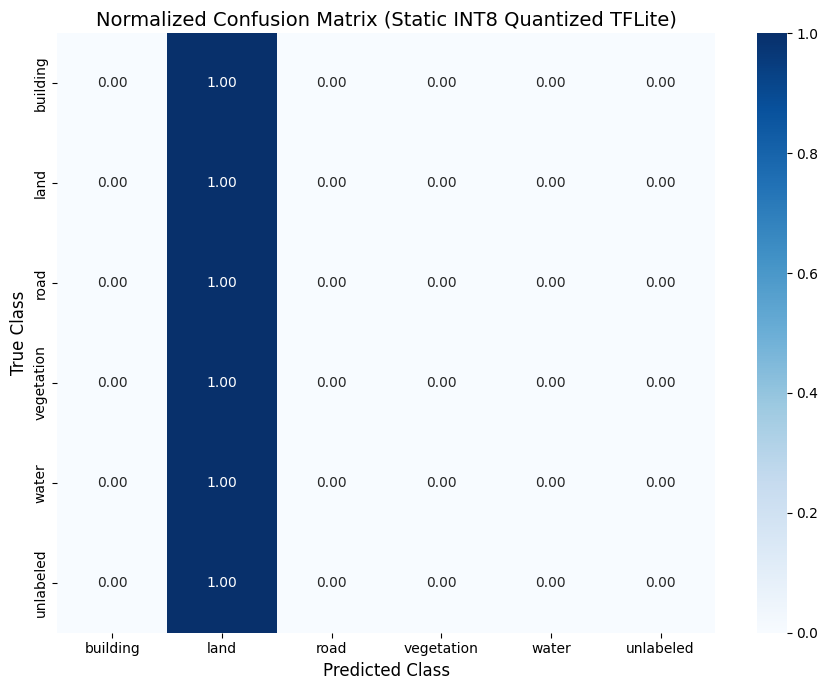


✅ Metrics table saved to: static_int8_quantized_metrics.csv (and Google Drive)
✅ Confusion matrix plot saved to: confusion_matrix_static_int8.png (and Google Drive)


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import shutil
from sklearn.metrics import confusion_matrix

# 1. Confusion Matrix
classes = label_names
cm = confusion_matrix(all_true_static, all_pred_static, labels=range(len(classes)))

# 2. Compute Per-Class IoU, Dice, Precision, Recall
intersection = np.diag(cm)
ground_truth_set = cm.sum(axis=1)
predicted_set = cm.sum(axis=0)
union = ground_truth_set + predicted_set - intersection

iou = intersection / np.maximum(union, 1e-7)
precision = intersection / np.maximum(predicted_set, 1e-7)
recall = intersection / np.maximum(ground_truth_set, 1e-7)
f1_dice = (2 * intersection) / np.maximum(ground_truth_set + predicted_set, 1e-7)

# 3. Create DataFrame
static_metrics_df = pd.DataFrame({
    'Class': classes,
    'Static INT8 IoU': np.round(iou, 4),
    'Static INT8 Dice / F1': np.round(f1_dice, 4),
    'Precision': np.round(precision, 4),
    'Recall': np.round(recall, 4)
})

# Summary Rows: Overall Mean and 5 Genuine Terrain Classes
overall_row = pd.DataFrame([{
    'Class': 'Mean (mIoU / Overall)',
    'Static INT8 IoU': np.round(np.mean(iou), 4),
    'Static INT8 Dice / F1': np.round(np.mean(f1_dice), 4),
    'Precision': np.round(np.mean(precision), 4),
    'Recall': np.round(np.mean(recall), 4)
}])

terrain_row = pd.DataFrame([{
    'Class': '5-Class Terrain mIoU',
    'Static INT8 IoU': np.round(np.mean(iou[:5]), 4),
    'Static INT8 Dice / F1': np.round(np.mean(f1_dice[:5]), 4),
    'Precision': np.round(np.mean(precision[:5]), 4),
    'Recall': np.round(np.mean(recall[:5]), 4)
}])

static_metrics_df = pd.concat([static_metrics_df, overall_row, terrain_row], ignore_index=True)

# Save CSV locally and copy to Drive
csv_name = "static_int8_quantized_metrics.csv"
static_metrics_df.to_csv(csv_name, index=False)
shutil.copy(csv_name, f"/content/drive/MyDrive/MBRSC dataset/models/{csv_name}")

print("\n=== STATIC INT8 TFLITE METRICS SUMMARY ===")
display(static_metrics_df)

# 4. Plot and Save Normalized Confusion Matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=classes, yticklabels=classes, cbar=True)
plt.title("Normalized Confusion Matrix (Static INT8 Quantized TFLite)", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("True Class", fontsize=12)
plt.tight_layout()

plot_name = "confusion_matrix_static_int8.png"
plt.savefig(plot_name, dpi=200)
shutil.copy(plot_name, f"/content/drive/MyDrive/MBRSC dataset/models/{plot_name}")
plt.show()

print(f"\n✅ Metrics table saved to: {csv_name} (and Google Drive)")
print(f"✅ Confusion matrix plot saved to: {plot_name} (and Google Drive)")